# Project 2 — Concrete Compressive Strength


In [1]:
# importing packages
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, GroupKFold, GroupShuffleSplit, KFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = "C:/Users/Irenenm/Desktop/masters2025/YR 2 SEM 11/Data Mining/Concrete_Data.csv"

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Original column names:", list(raw.columns))
raw.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer",
               "coarse_agg", "fine_agg", "age", "strength"]
COMPONENTS = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg"]
print("Shape:", raw.shape)
raw.head()

Original column names: ['Cement (kg in a m^3 mixture)', 'Blast Furnace Slag (kg in a m^3 mixture)', 'Fly Ash (kg in a m^3 mixture)', 'Water (kg in a m^3 mixture)', 'Superplasticizer (kg in a m^3 mixture)', 'Coarse Aggregate (kg in a m^3 mixture)', 'Fine Aggregate (kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength (MPa, megapascals) ']
Shape: (1030, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.000,0.000,0.000,162.000,2.500,"1,040.000",676.000,28,79.986
1,540.000,0.000,0.000,162.000,2.500,"1,055.000",676.000,28,61.887
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270,40.270
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365,41.053
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360,44.296


## 2. Exploratory data analysis

### 2.1 Summary statistics, missing values and duplicates

In [3]:
print("Missing values per column:", raw.isna().sum().to_dict())
print("Exact duplicate rows:", raw.duplicated().sum())
display(raw.describe().T)

zeros = (raw[COMPONENTS] == 0).mean().rename("share of zeros")
display(zeros[zeros > 0].to_frame())

Missing values per column: {'cement': 0, 'slag': 0, 'fly_ash': 0, 'water': 0, 'superplasticizer': 0, 'coarse_agg': 0, 'fine_agg': 0, 'age': 0, 'strength': 0}
Exact duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max
cement,"1,030.000",281.166,104.507,102.000,192.375,272.900,350.000,540.000
slag,"1,030.000",73.895,86.279,0.000,0.000,22.000,142.950,359.400
fly_ash,"1,030.000",54.187,63.996,0.000,0.000,0.000,118.270,200.100
water,"1,030.000",181.566,21.356,121.750,164.900,185.000,192.000,247.000
superplasticizer,"1,030.000",6.203,5.973,0.000,0.000,6.350,10.160,32.200
coarse_agg,"1,030.000",972.919,77.754,801.000,932.000,968.000,"1,029.400","1,145.000"
fine_agg,"1,030.000",773.579,80.175,594.000,730.950,779.510,824.000,992.600
age,"1,030.000",45.662,63.170,1.000,7.000,28.000,56.000,365.000
strength,"1,030.000",35.818,16.706,2.332,23.707,34.443,46.136,82.599


,share of zeros
slag,0.452
fly_ash,0.550
superplasticizer,0.368


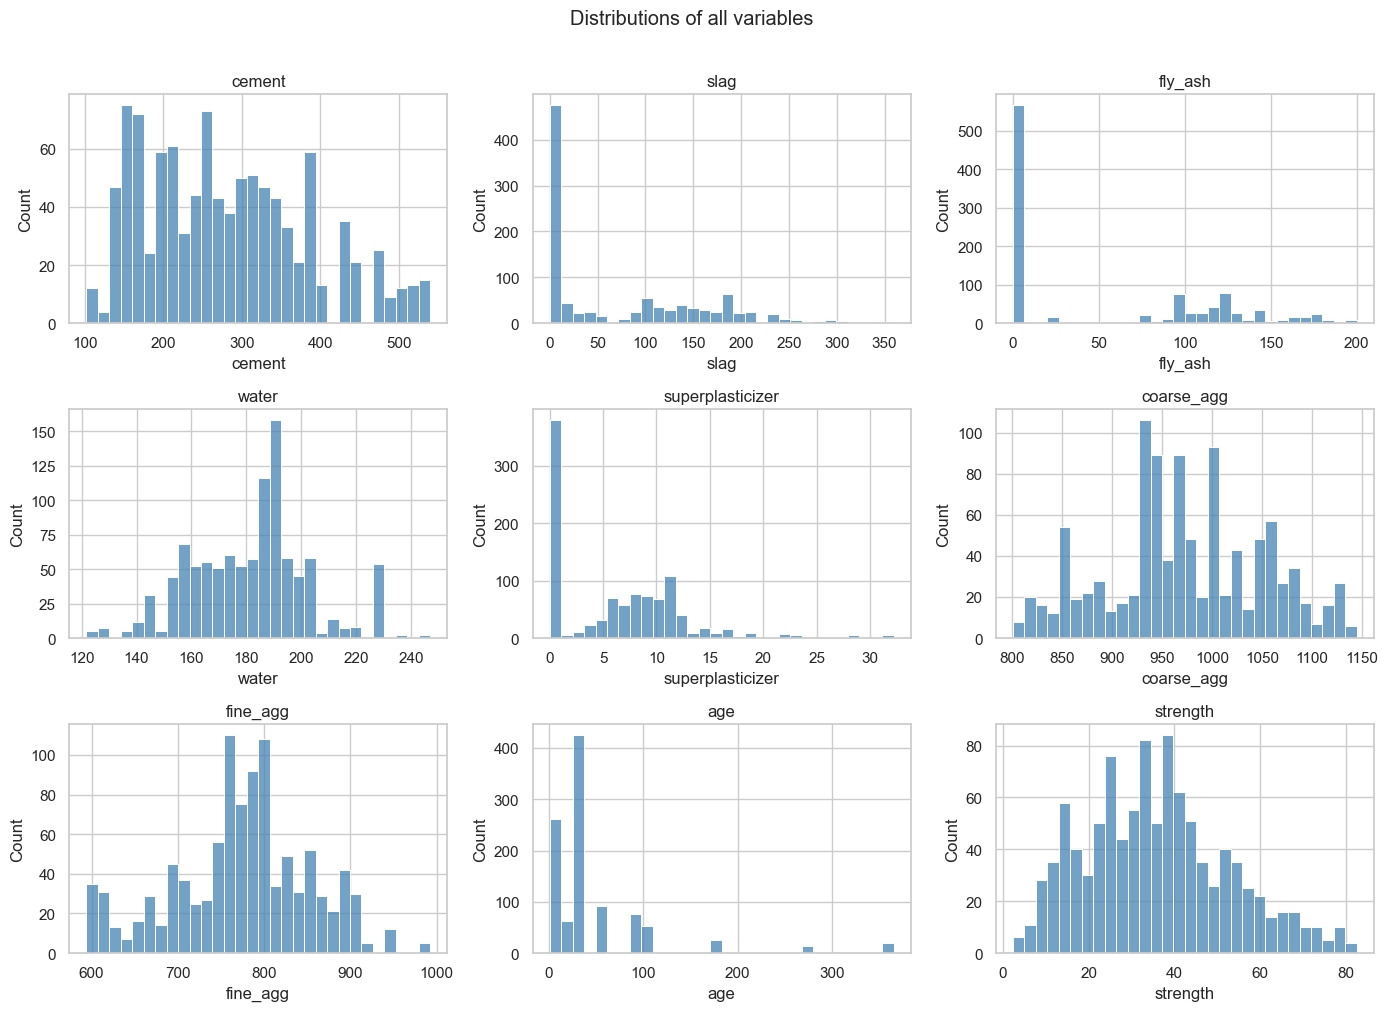

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), raw.columns):
    sns.histplot(raw[col], bins=30, ax=ax, color="steelblue")
    ax.set_title(col)
plt.suptitle("Distributions of all variables", y=1.01)
plt.tight_layout(); plt.show()

### 2.2 Curing age — a discrete, uneven design variable

Number of samples at each age (days):
{1: 2, 3: 134, 7: 126, 14: 62, 28: 425, 56: 91, 90: 54, 91: 22, 100: 52, 120: 3, 180: 26, 270: 13, 360: 6, 365: 14}


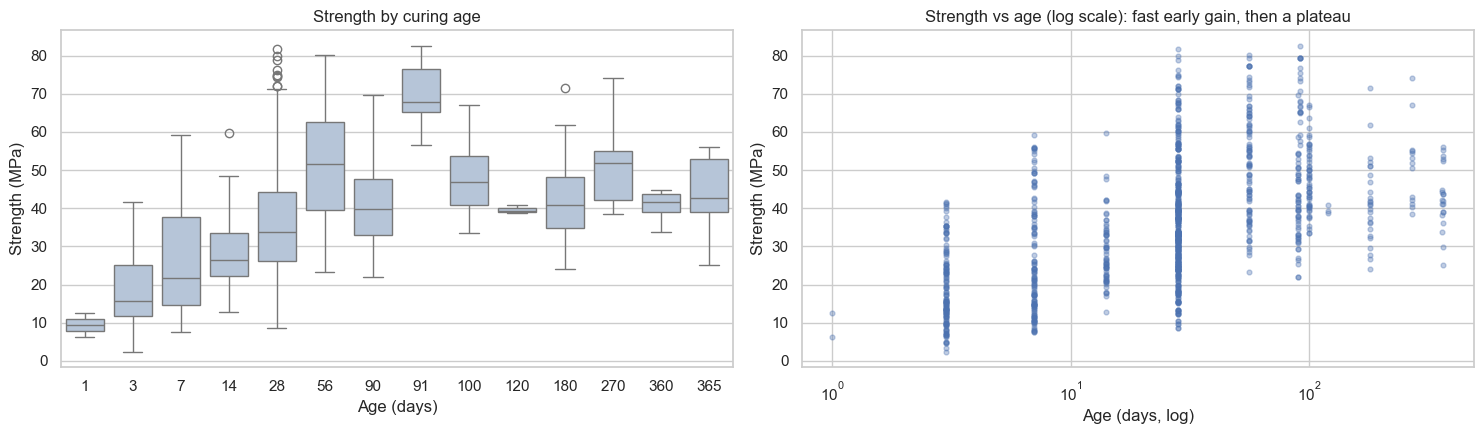

In [5]:
age_counts = raw["age"].value_counts().sort_index()
print("Number of samples at each age (days):"); print(age_counts.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(x="age", y="strength", data=raw, ax=axes[0], color="lightsteelblue")
axes[0].set(title="Strength by curing age", xlabel="Age (days)", ylabel="Strength (MPa)")
axes[1].scatter(raw["age"], raw["strength"], alpha=.35, s=12)
axes[1].set_xscale("log")
axes[1].set(title="Strength vs age (log scale): fast early gain, then a plateau", xlabel="Age (days, log)", ylabel="Strength (MPa)")
plt.tight_layout(); plt.show()

### 2.3 Relationships between variables

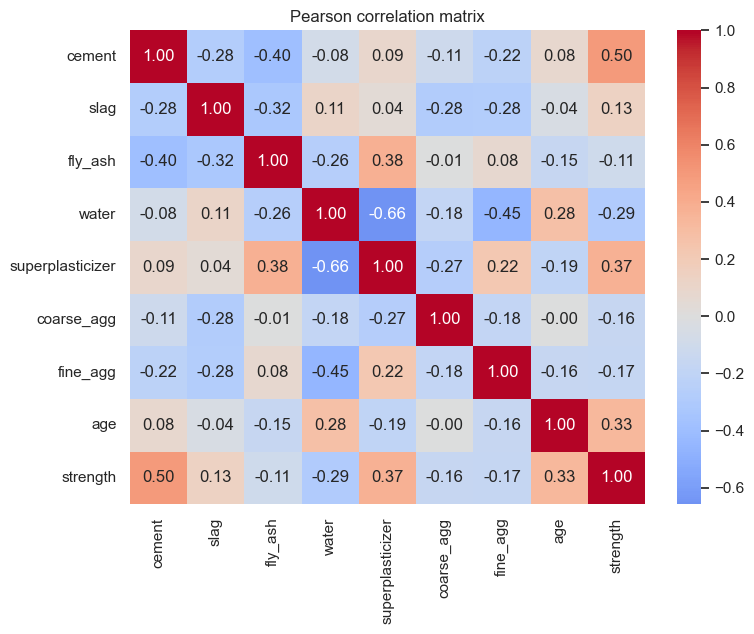

In [6]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(raw.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Pearson correlation matrix"); plt.tight_layout(); plt.show()

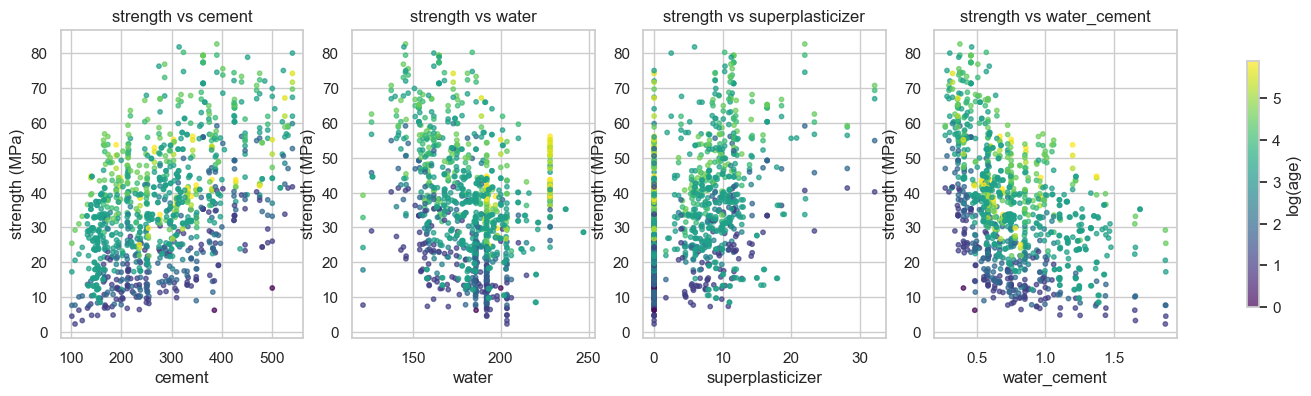

Spearman correlation, strength vs water/cement ratio: -0.522 (vs cement alone: 0.478)


In [7]:
tmp = raw.assign(water_cement=raw["water"] / raw["cement"])
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["cement", "water", "superplasticizer", "water_cement"]):
    sc = ax.scatter(tmp[col], tmp["strength"], c=np.log(tmp["age"]), cmap="viridis", s=10, alpha=.7)
    ax.set(xlabel=col, ylabel="strength (MPa)", title=f"strength vs {col}")
cb = fig.colorbar(sc, ax=axes, shrink=.8); cb.set_label("log(age)")
plt.show()
r_wc, _ = stats.spearmanr(tmp["water_cement"], tmp["strength"])
print(f"Spearman correlation, strength vs water/cement ratio: {r_wc:.3f} "
      f"(vs cement alone: {stats.spearmanr(tmp['cement'], tmp['strength'])[0]:.3f})")

### 2.4 Structure of the data: the same mixture is tested at several ages

In [8]:
mix_id = raw[COMPONENTS].round(3).astype(str).agg("|".join, axis=1)
mix_sizes = mix_id.value_counts()
print(f"Rows: {len(raw)}  |  distinct mixtures: {mix_id.nunique()}")
print(f"Mixtures tested at more than one age: {(mix_sizes > 1).sum()}, covering {mix_sizes[mix_sizes > 1].sum()} rows")
print("Rows per mixture:", mix_sizes.value_counts().sort_index().to_dict())

total = raw[COMPONENTS].sum(axis=1)
print(f"\nTotal mass of ingredients per m^3: mean {total.mean():.0f} kg, range {total.min():.0f}-{total.max():.0f} kg "
      f"(sd {total.std():.0f} kg) - a nearly fixed budget")
display(raw[COMPONENTS].corr().loc[["cement"], ["slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg"]])

Rows: 1030  |  distinct mixtures: 428
Mixtures tested at more than one age: 182, covering 784 rows
Rows per mixture: {1: 246, 2: 41, 3: 8, 4: 38, 5: 76, 6: 11, 7: 3, 8: 3, 15: 1, 20: 1}

Total mass of ingredients per m^3: mean 2344 kg, range 2195-2551 kg (sd 65 kg) - a nearly fixed budget


,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg
cement,-0.275,-0.397,-0.082,0.093,-0.109,-0.223


### 2.5 Data report

**Structure.** The dataset has 1,030 laboratory tests with eight numeric predictors: seven ingredients in kg/m³, plus age in days. The target is compressive strength in MPa (mean ≈ 35.8, sd ≈ 16.7, range 2.3–82.6). Yeh (1998) compiled the data from 17 separate laboratory sources.

**Key findings.**
1. **No missing values, but 25 exact duplicate rows.** They are identical down to the eighth decimal of strength, which suggests repeated records rather than independent replicate tests.
2. **Zeros are structural, not missing.** Slag, fly ash and superplasticizer are optional ingredients. They are absent (0) in about 45%, 55% and 37% of mixes respectively, so their distributions are zero-inflated.
3. **Age is a discrete design variable** with 14 levels. 28 days (the standard test age) accounts for about 41% of rows, while ages above 100 days are rare. Strength rises steeply in the first month and then levels off, a clearly **non-linear (roughly logarithmic) curve**.
4. **The strongest individual correlates** are cement (+0.50), superplasticizer (+0.37), age (+0.33) and water (−0.29). The **water-to-cement ratio** is more strongly related to strength than cement alone, consistent with Abrams' law (Abrams, 1919): strength falls as the w/c ratio rises.
5. **The data are grouped.** There are only 428 distinct mixtures. Many are tested at several ages, so rows are *not* independent. If a random split puts the same mix (at different ages) in both the training and test sets, performance will look better than it really is. We therefore validate **by mixture** (grouped CV).
6. **The ingredients are interdependent.** The total mass per m³ is nearly constant, and cement is negatively correlated with slag and fly ash, which replace part of the cement. One ingredient cannot change without others changing. This matters for interpretation (Section 10).

**Limitations.** The data come from many laboratories with different materials and testing practices, which adds noise. There are no variables for cement type, aggregate type, temperature or humidity. Some regions of the mixture space, such as very old or very high-strength samples, are sparsely sampled.

## 3. Data preparation

| Step | Decision | Justification |
|---|---|---|
| Duplicates | Remove the 25 exact duplicates | Copies could fall in both training and test sets and inflate the scores. |
| Zeros in slag, fly ash, superplasticizer | Keep as real zeros | They mean "ingredient not used". Imputing them would be wrong. |
| Outliers | Keep all values | All values are physically plausible. Removing extremes would make the model look better than it is in exactly the areas we need to study. |
| Feature engineering | Add `log_age`, `water_cement` (w/c) and `water_binder` (water / (cement + slag + fly ash)) | Based on concrete science: strength grows roughly logarithmically with age, and Abrams' law links strength to the w/c ratio (Neville, 2011). This gives the *linear* models a fair chance to capture known non-linearity. |
| Scaling | Standardise inputs for linear models and SVR (inside pipelines) | Needed for regularisation and kernel methods. Trees do not need it. |
| Split | Hold out 20% of **mixtures** as a test set (`GroupShuffleSplit`), then use 5-fold **GroupKFold** on the training set | Prevents the same mix appearing in both training and validation data (Roberts et al., 2017). |

In [9]:
data = raw.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(data))

data["log_age"] = np.log(data["age"])
data["water_cement"] = data["water"] / data["cement"]
data["water_binder"] = data["water"] / (data["cement"] + data["slag"] + data["fly_ash"])
data["mix_id"] = data[COMPONENTS].round(3).astype(str).agg("|".join, axis=1).factorize()[0]

RAW_FEATURES = COMPONENTS + ["age"]
ENG_FEATURES = RAW_FEATURES + ["log_age", "water_cement", "water_binder"]
TARGET = "strength"

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(data, groups=data["mix_id"]))
train, test = data.iloc[train_idx].copy(), data.iloc[test_idx].copy()
groups_train = train["mix_id"].to_numpy()
y_train, y_test = train[TARGET], test[TARGET]
print(f"Train: {len(train)} rows / {train['mix_id'].nunique()} mixtures | "
      f"Test: {len(test)} rows / {test['mix_id'].nunique()} mixtures")
print("Mixtures shared between train and test:", len(set(train["mix_id"]) & set(test["mix_id"])))

GCV = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Rows after removing duplicates: 1005
Train: 799 rows / 342 mixtures | Test: 206 rows / 86 mixtures
Mixtures shared between train and test: 0


In [10]:
def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def reg_metrics(y, p):
    return {"RMSE": rmse(y, p), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

## 4. Mean-prediction baseline

The baseline predicts the training-set mean strength for every sample. A model is only useful if its error is clearly below this.

In [11]:
baseline = DummyRegressor(strategy="mean")
cv_base = cross_validate(baseline, train[RAW_FEATURES], y_train, groups=groups_train, cv=GCV,
                         scoring={"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"})
baseline.fit(train[RAW_FEATURES], y_train)
base_test = reg_metrics(y_test, baseline.predict(test[RAW_FEATURES]))
print(f"Training mean used as prediction: {y_train.mean():.2f} MPa")
print(f"Grouped-CV RMSE: {-cv_base['test_RMSE'].mean():.2f} ± {cv_base['test_RMSE'].std():.2f} MPa")
display(pd.DataFrame(base_test, index=["Mean baseline (test)"]))

Training mean used as prediction: 34.97 MPa
Grouped-CV RMSE: 15.86 ± 1.40 MPa


,RMSE,MAE,R2
Mean baseline (test),18.016,14.476,-0.006


## 5. Linear vs non-linear modelling approaches

| Family | Model | Why it is included |
|---|---|---|
| Linear | **Linear regression — raw inputs** | The simplest additive model on the eight original variables. It is the reference for "linear". |
| Linear | **Linear regression — engineered inputs** | Still linear in its parameters, but adds `log_age`, w/c and water/binder ratios from domain knowledge. It tests how far a linear model can go with good features. |
| Linear (in parameters) | **Polynomial ridge (degree 2)** | Adds all pairwise interactions and squares, with an L2 penalty against overfitting. It sits between the linear and fully non-linear models. |
| Non-linear | **Random forest** (Breiman, 2001) | Averages many deep trees and captures interactions automatically. |
| Non-linear | **Gradient boosting** (Friedman, 2001) | Adds shallow trees one at a time, each correcting the previous errors. Often the most accurate approach on small tabular datasets. |
| Non-linear | **Support vector regression (RBF kernel)** | A smooth kernel method, representative of the neural/kernel models used in early studies of this dataset (Yeh, 1998). |

Non-linear models get the engineered feature set too, so the comparison is about **model flexibility**, not about features. Each model is tuned with a small grid search on the same grouped 5-fold CV, minimising RMSE.

In [12]:
candidates = {
    "Linear regression (raw)": (Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]), {}, RAW_FEATURES, "linear"),
    "Linear regression (engineered)": (Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]), {}, ENG_FEATURES, "linear"),
    "Polynomial ridge (degree 2)": (Pipeline([("sc", StandardScaler()), ("poly", PolynomialFeatures(2, include_bias=False)),
                                              ("sc2", StandardScaler()), ("m", Ridge())]),
                                    {"m__alpha": [0.1, 1, 10, 100]}, ENG_FEATURES, "linear"),
    "Random forest": (RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
                      {"min_samples_leaf": [1, 3], "max_features": [0.5, 1.0]}, ENG_FEATURES, "non-linear"),
    "Gradient boosting": (GradientBoostingRegressor(learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
                          {"n_estimators": [500, 1000], "max_depth": [3, 5]}, ENG_FEATURES, "non-linear"),
    "SVR (RBF kernel)": (Pipeline([("sc", StandardScaler()), ("m", SVR(epsilon=1.0))]),
                         {"m__C": [10, 100, 300], "m__gamma": ["scale", 0.3]}, ENG_FEATURES, "non-linear"),
}

scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
fitted, cv_rows, fold_rmse = {}, [], {}
for name, (est, grid, feats, family) in candidates.items():
    gs = GridSearchCV(est, grid or {}, scoring=scoring, refit="RMSE", cv=GCV, n_jobs=1)
    gs.fit(train[feats], y_train, groups=groups_train)
    i, r = gs.best_index_, gs.cv_results_
    fitted[name] = (gs.best_estimator_, feats, family)
    fold_rmse[name] = [-r[f"split{k}_test_RMSE"][i] for k in range(5)]
    cv_rows.append({"Model": name, "Family": family, "Best params": gs.best_params_,
                    "CV RMSE": -r["mean_test_RMSE"][i], "CV RMSE sd": r["std_test_RMSE"][i],
                    "CV MAE": -r["mean_test_MAE"][i], "CV R2": r["mean_test_R2"][i]})
cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.loc["Mean baseline"] = ["baseline", {}, -cv_base["test_RMSE"].mean(), cv_base["test_RMSE"].std(),
                                 -cv_base["test_MAE"].mean(), cv_base["test_R2"].mean()]
display(cv_table.sort_values("CV RMSE"))

,Family,Best params,CV RMSE,CV RMSE sd,CV MAE,CV R2
Model,,,,,,
Gradient boosting,non-linear,"{'max_depth': 3, 'n_estimators': 1000}",5.222,0.592,3.883,0.887
Random forest,non-linear,"{'max_features': 0.5, 'min_samples_leaf': 1}",5.540,0.896,4.064,0.873
SVR (RBF kernel),non-linear,"{'m__C': 100, 'm__gamma': 'scale'}",5.955,0.804,4.276,0.854
Polynomial ridge (degree 2),linear,{'m__alpha': 10},6.371,0.749,4.796,0.832
Linear regression (engineered),linear,{},6.945,0.778,5.527,0.799
Linear regression (raw),linear,{},10.300,0.848,8.198,0.559
Mean baseline,baseline,{},15.861,1.398,12.872,-0.042


,Linear regression (raw),Linear regression (engineered),Polynomial ridge (degree 2),Random forest,Gradient boosting,SVR (RBF kernel)
fold 1,9.79,6.94,5.96,4.75,4.75,5.17
fold 2,11.13,7.48,7.75,6.00,5.86,7.22
fold 3,9.83,6.33,6.05,5.52,5.03,5.94
fold 4,9.27,5.90,5.58,4.47,4.50,5.04
fold 5,11.47,8.07,6.52,6.96,5.97,6.40


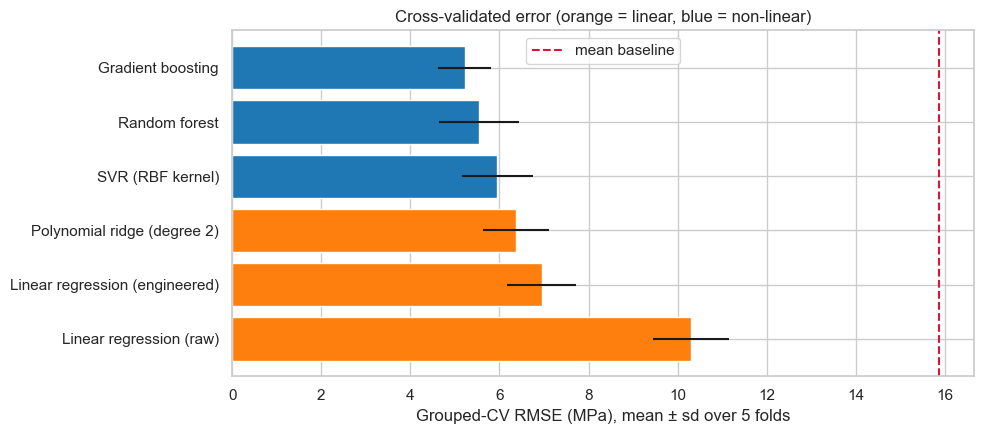

In [13]:
folds = pd.DataFrame(fold_rmse, index=[f"fold {k+1}" for k in range(5)])
display(folds.style.format("{:.2f}").highlight_min(axis=1, color="#c6efce"))

fig, ax = plt.subplots(figsize=(10, 4.5))
order = cv_table.drop(index="Mean baseline").sort_values("CV RMSE").index
pal = {"linear": "tab:orange", "non-linear": "tab:blue"}
ax.barh(order, cv_table.loc[order, "CV RMSE"], xerr=cv_table.loc[order, "CV RMSE sd"],
        color=[pal[cv_table.loc[n, "Family"]] for n in order])
ax.axvline(cv_table.loc["Mean baseline", "CV RMSE"], color="crimson", ls="--", label="mean baseline")
ax.invert_yaxis(); ax.set(xlabel="Grouped-CV RMSE (MPa), mean ± sd over 5 folds", title="Cross-validated error (orange = linear, blue = non-linear)")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Held-out test comparison

Each tuned model is refitted on all training mixtures and scored **once** on the unseen test mixtures.

In [14]:
test_pred = {n: m.predict(test[f]) for n, (m, f, fam) in fitted.items()}
test_table = pd.DataFrame({n: reg_metrics(y_test, p) for n, p in test_pred.items()}).T
test_table["Family"] = [fitted[n][2] for n in test_table.index]
test_table.loc["Mean baseline"] = [*base_test.values(), "baseline"]
test_table["RMSE reduction vs baseline"] = 1 - test_table["RMSE"].astype(float) / base_test["RMSE"]
display(test_table.sort_values("RMSE"))

,RMSE,MAE,R2,Family,RMSE reduction vs baseline
Gradient boosting,5.773,3.958,0.897,non-linear,0.680
Random forest,5.807,4.097,0.895,non-linear,0.678
SVR (RBF kernel),6.044,3.925,0.887,non-linear,0.665
Polynomial ridge (degree 2),7.141,4.970,0.842,linear,0.604
Linear regression (engineered),7.436,5.605,0.829,linear,0.587
Linear regression (raw),10.792,8.678,0.639,linear,0.401
Mean baseline,18.016,14.476,-0.006,baseline,0.000


In [15]:
lin_names = [n for n in fitted if fitted[n][2] == "linear"]
nl_names = [n for n in fitted if fitted[n][2] == "non-linear"]
best_lin = min(lin_names, key=lambda n: cv_table.loc[n, "CV RMSE"])
best_nl = min(nl_names, key=lambda n: cv_table.loc[n, "CV RMSE"])
print(f"Best linear model (by CV): {best_lin}  |  best non-linear model (by CV): {best_nl}")

rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
test_groups = test["mix_id"].to_numpy()
uniq = np.unique(test_groups)
pairs = [(best_lin, best_nl), ("Linear regression (raw)", best_nl), ("Linear regression (raw)", best_lin)]
diffs = {p: [] for p in pairs}
for _ in range(2000):                      # cluster bootstrap: resample whole mixtures
    gs_ = rng.choice(uniq, len(uniq), replace=True)
    idx = np.concatenate([np.flatnonzero(test_groups == g) for g in gs_])
    for a, b in pairs:
        diffs[(a, b)].append(rmse(yt[idx], test_pred[a][idx]) - rmse(yt[idx], test_pred[b][idx]))
rows = [{"Comparison (RMSE of A minus RMSE of B)": f"A = {a}  |  B = {b}", "Mean difference (MPa)": np.mean(d),
         "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5)} for (a, b), d in diffs.items()]
display(pd.DataFrame(rows))

Best linear model (by CV): Polynomial ridge (degree 2)  |  best non-linear model (by CV): Gradient boosting


,Comparison (RMSE of A minus RMSE of B),Mean difference (MPa),95% CI low,95% CI high
0,A = Polynomial ridge (degree 2) | B = Gradie...,1.309,-0.332,3.212
1,A = Linear regression (raw) | B = Gradient b...,5.004,4.011,5.979
2,A = Linear regression (raw) | B = Polynomial...,3.695,1.707,5.233


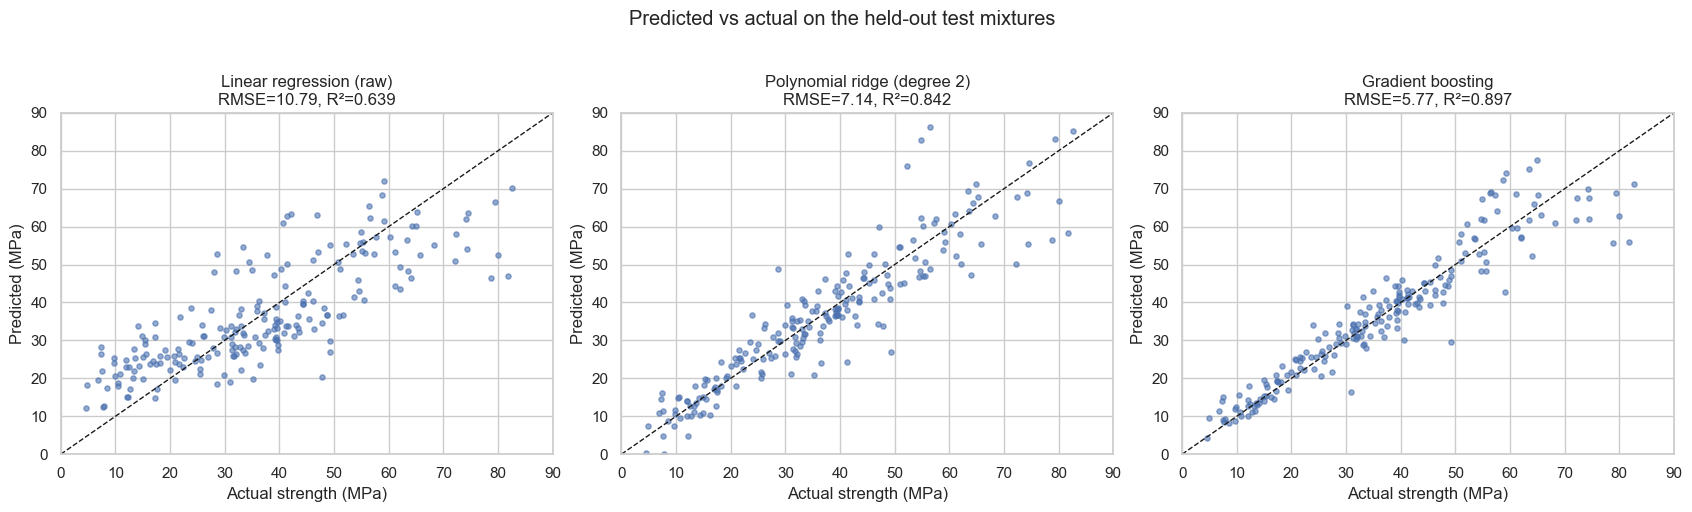

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, n in zip(axes, ["Linear regression (raw)", best_lin, best_nl]):
    p = test_pred[n]
    ax.scatter(y_test, p, s=14, alpha=.6)
    lim = [0, 90]; ax.plot(lim, lim, "k--", lw=1)
    ax.set(xlim=lim, ylim=lim, xlabel="Actual strength (MPa)", ylabel="Predicted (MPa)",
           title=f"{n}\nRMSE={rmse(y_test, p):.2f}, R²={r2_score(y_test, p):.3f}")
plt.suptitle("Predicted vs actual on the held-out test mixtures", y=1.02)
plt.tight_layout(); plt.show()

### 6.1 Linear vs non-linear:

| Evidence | Result |
|---|---|
| Grouped-CV RMSE (MPa) | Gradient boosting **5.22**, random forest 5.53, SVR 5.96. Polynomial ridge 6.37, engineered linear 6.95, raw linear **10.30**. Mean baseline 15.86. |
| Held-out test RMSE (MPa) | Gradient boosting **5.68** (R² 0.90), random forest 5.81, SVR 6.04. Polynomial ridge 7.14, engineered linear 7.44, raw linear 10.79 (R² 0.64). Baseline 18.02. |
| Fold by fold | A non-linear model is best in **all 5 folds**, and gradient boosting beats the best linear model in every fold. |
| Different fold assignments (Sec. 9) | Gradient boosting beats polynomial ridge in **all 5 random seeds**, by 1.0–1.45 MPa. |
| Test-set bootstrap (resampling whole mixtures) | Raw linear minus gradient boosting: +5.1 MPa (95% CI 4.2–6.0). Polynomial ridge minus gradient boosting: +1.4 MPa (95% CI −0.2 to 3.3). |

**Interpretation**
- Every model beats the mean baseline by a wide margin. Gradient boosting cuts the baseline's test RMSE by about 69%.
- The **plain linear model is clearly inadequate** (R² of about 0.6), because strength depends non-linearly on age and on ingredient ratios.
- **Domain-informed features close most of the gap.** Adding log(age) and the w/c and water/binder ratios lowers the linear model's RMSE from 10.3 to 6.9. Adding interactions (polynomial ridge) lowers it to 6.4.
- Flexible non-linear models remain best. Gradient boosting improves on the best linear model by about 1.3 MPa, roughly 20% lower error. On the small test set (86 mixtures) the confidence interval for this difference just includes zero. The consistent advantage across every CV fold and every seed is stronger evidence that the gain is real.
- **Conclusion:** gradient boosting is the most accurate model. The engineered linear model is a reasonable, interpretable second choice when transparency matters.

## 7. Checking the linear model's assumptions

Ordinary least squares assumes that the relationship is linear, that the errors have constant variance (homoscedasticity) and are roughly normal, and that the predictors are not strongly collinear. We check these for the **raw** and the **engineered** linear models using residuals from the training fit.

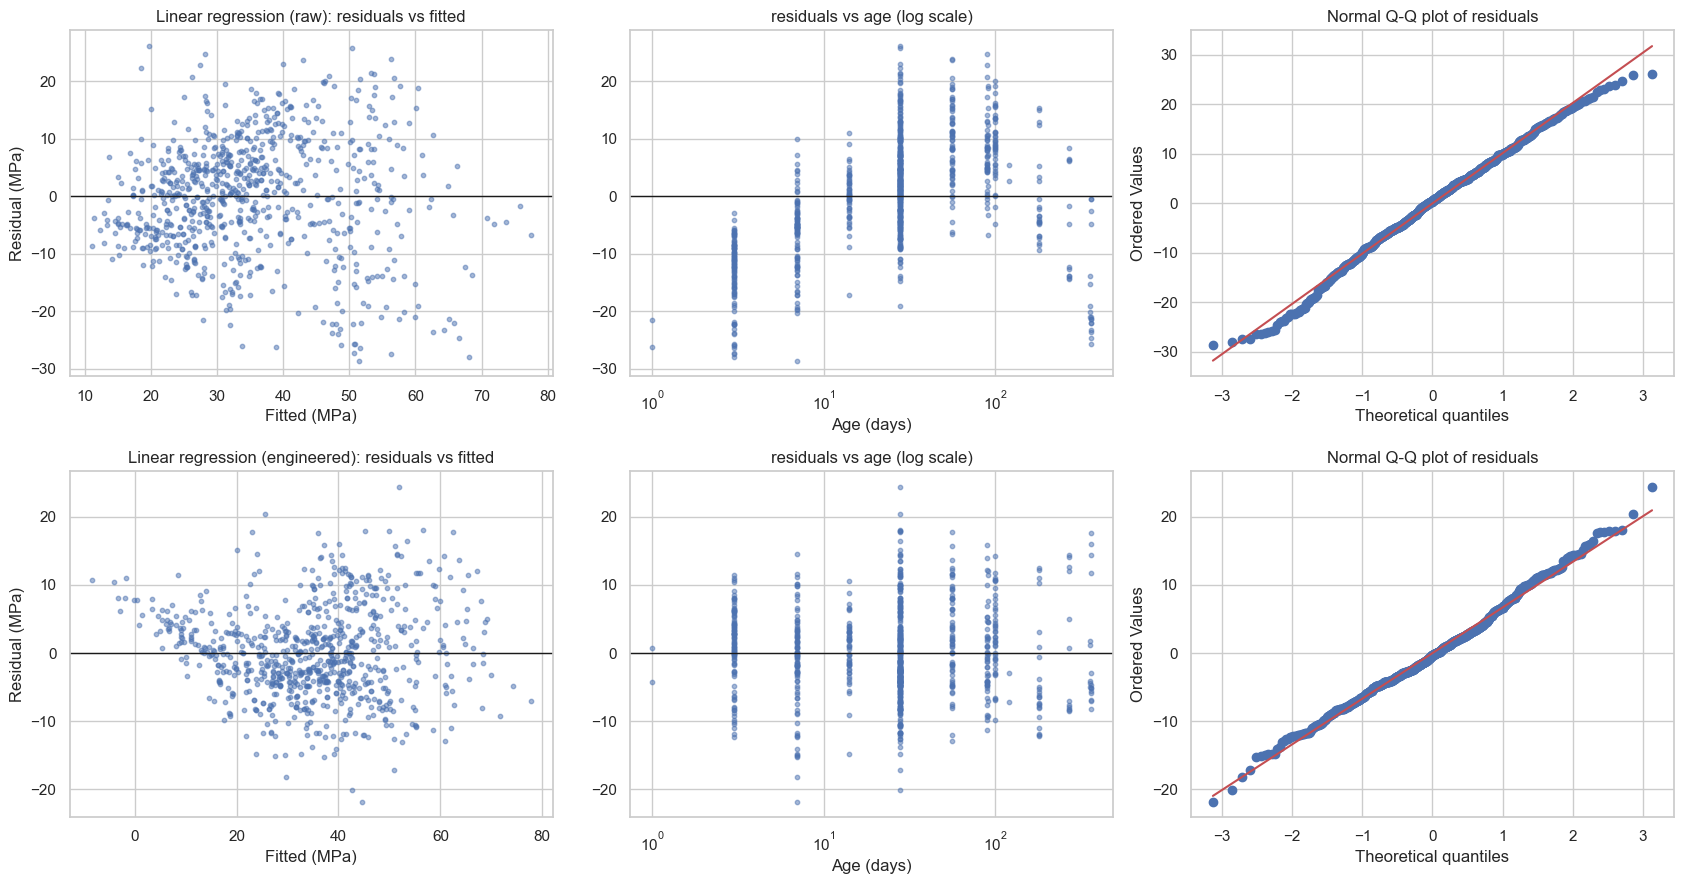

,Breusch-Pagan LM,BP p-value,Shapiro-Wilk W,SW p-value,Residual skew,Max VIF
Model,,,,,,
Linear regression (raw),107.577,0.000,0.995,0.006,-0.219,7.369
Linear regression (engineered),74.227,0.000,0.994,0.003,0.241,24.345


Mean residual (actual - fitted, MPa) by age - a systematic pattern signals a misspecified functional form:


age,1,3,7,14,28,56,90,91,100,120,180,270,360,365
Linear regression (raw),-23.950,-13.315,-6.712,0.057,2.947,9.218,7.696,8.401,9.226,4.080,-0.754,-5.026,-17.891,-16.419
Linear regression (engineered),-1.684,1.051,-1.106,0.549,-0.615,2.450,-0.669,2.270,2.776,-5.042,-3.516,0.932,-2.097,0.683


VIF for the raw linear model's predictors:


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age
VIF,6.883,7.161,5.759,6.976,2.835,4.577,7.369,1.133


In [18]:
def vif_table(X):
    out = {}
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name="VIF")

def breusch_pagan(X, resid):
    # LM statistic: n * R^2 of the regression of squared residuals on X; ~ chi2(k)
    e2 = resid ** 2
    r2 = LinearRegression().fit(X, e2).score(X, e2)
    lm = len(e2) * r2
    return lm, 1 - stats.chi2.cdf(lm, X.shape[1])

diag_rows = []
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for row, n in enumerate(["Linear regression (raw)", "Linear regression (engineered)"]):
    m, f, _ = fitted[n]
    fit_vals = m.predict(train[f]); resid = y_train.to_numpy() - fit_vals
    lm, p_bp = breusch_pagan(train[f], resid)
    sh_w, p_sw = stats.shapiro(resid)
    diag_rows.append({"Model": n, "Breusch-Pagan LM": lm, "BP p-value": p_bp, "Shapiro-Wilk W": sh_w,
                      "SW p-value": p_sw, "Residual skew": stats.skew(resid), "Max VIF": vif_table(train[f]).max()})
    axes[row, 0].scatter(fit_vals, resid, s=10, alpha=.5); axes[row, 0].axhline(0, color="k", lw=1)
    axes[row, 0].set(title=f"{n}: residuals vs fitted", xlabel="Fitted (MPa)", ylabel="Residual (MPa)")
    axes[row, 1].scatter(train["age"], resid, s=10, alpha=.5); axes[row, 1].set_xscale("log"); axes[row, 1].axhline(0, color="k", lw=1)
    axes[row, 1].set(title="residuals vs age (log scale)", xlabel="Age (days)")
    stats.probplot(resid, dist="norm", plot=axes[row, 2]); axes[row, 2].set_title("Normal Q-Q plot of residuals")
plt.tight_layout(); plt.show()
display(pd.DataFrame(diag_rows).set_index("Model"))
bias_by_age = {}
for n in ["Linear regression (raw)", "Linear regression (engineered)"]:
    m, f, _ = fitted[n]
    bias_by_age[n] = (y_train - m.predict(train[f])).groupby(train["age"]).mean()
print("Mean residual (actual - fitted, MPa) by age - a systematic pattern signals a misspecified functional form:")
display(pd.DataFrame(bias_by_age).T)
print("VIF for the raw linear model's predictors:")
display(vif_table(train[RAW_FEATURES]).to_frame().T)

**Findings**
- **Linearity is violated for the raw model.** Its residuals depend strongly on age. It over-predicts very young concrete (about −13 MPa at 3 days, −24 MPa at 1 day), under-predicts at 56–100 days (about +9 MPa), and over-predicts again at 360–365 days (about −17 MPa). This is the signature of fitting a straight line to a logarithmic curve. The engineered model, using `log_age`, removes most of this pattern.
- **Constant variance is violated.** The Breusch–Pagan test rejects homoscedasticity for both models (p < 0.001). The residuals spread out as predicted strength increases. Point predictions are still unbiased, but OLS standard errors and prediction intervals would be unreliable without robust (heteroscedasticity-consistent) errors.
- **Normality is approximately satisfied.** Shapiro–Wilk rejects strict normality (p < 0.01), as it often does with about 800 observations. But W ≈ 0.99, skew is near 0 and the Q-Q plots are close to a straight line, so the departure is minor.
- **Collinearity.** VIFs for the raw inputs are moderate (up to about 7), caused by the near-fixed total mass of a mixture. In the engineered model, the ratios are built from cement and water, so VIF rises to about 24. This does not hurt prediction, but **individual coefficients cannot be read as separate effects of each ingredient** (relevant to Section 10).
- **Independence is violated.** Rows from the same mixture share errors (Section 8), which is why we validate by group.

## 8. Residual analysis — where are predictions weakest?

We use **out-of-fold** predictions for every training row (grouped CV) together with the test predictions. Every residual then comes from a model that did not see that mixture, which gives about 1,000 honest residuals. We compare the best linear model with the best non-linear model.

Residual = actual − predicted. A positive residual means the model **under-predicts** strength.

In [19]:
def oof_predict(name):
    m, f, _ = fitted[name]
    return cross_val_predict(clone(m), train[f], y_train, groups=groups_train, cv=GCV)

res = pd.concat([train.assign(split="train (out-of-fold)"), test.assign(split="test")])
for n, col in [(best_lin, "pred_linear"), (best_nl, "pred_nonlinear")]:
    res[col] = np.concatenate([oof_predict(n), test_pred[n]])
res["resid_linear"] = res[TARGET] - res["pred_linear"]
res["resid_nonlinear"] = res[TARGET] - res["pred_nonlinear"]
print(f"Out-of-fold + test RMSE - {best_lin}: {rmse(res[TARGET], res['pred_linear']):.2f} | "
      f"{best_nl}: {rmse(res[TARGET], res['pred_nonlinear']):.2f}")

Out-of-fold + test RMSE - Polynomial ridge (degree 2): 6.58 | Gradient boosting: 5.36


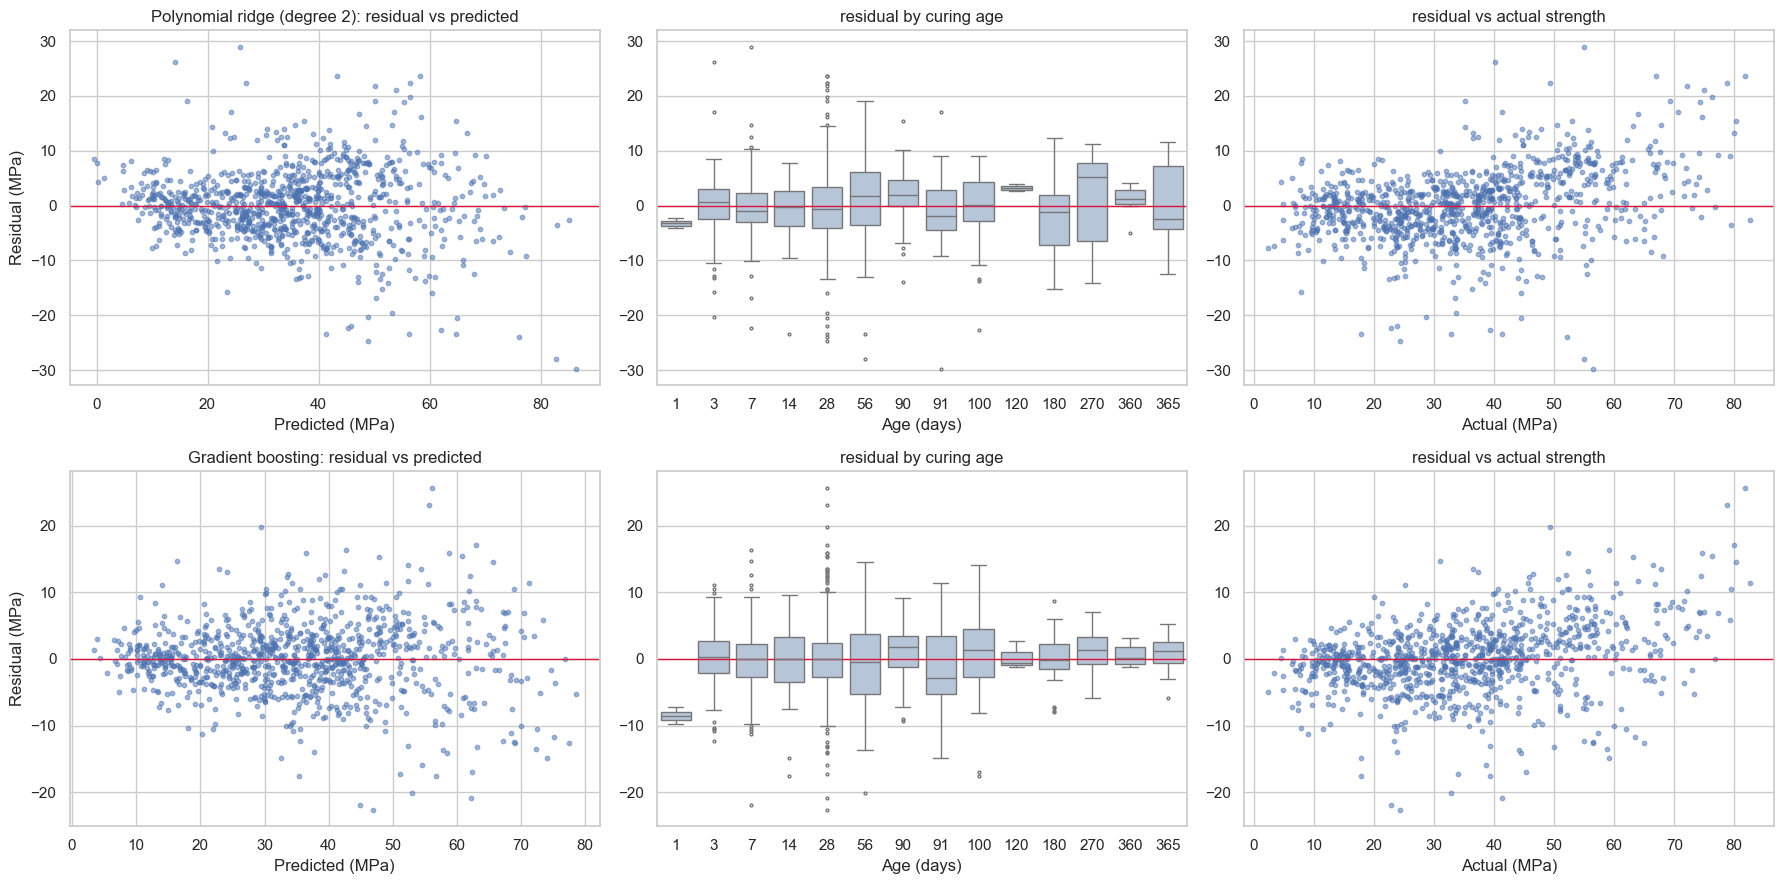

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for row, (lab, pc, rc) in enumerate([(best_lin, "pred_linear", "resid_linear"), (best_nl, "pred_nonlinear", "resid_nonlinear")]):
    axes[row, 0].scatter(res[pc], res[rc], s=10, alpha=.5)
    axes[row, 0].set(title=f"{lab}: residual vs predicted", xlabel="Predicted (MPa)", ylabel="Residual (MPa)")
    sns.boxplot(x="age", y=rc, data=res, ax=axes[row, 1], color="lightsteelblue", fliersize=2)
    axes[row, 1].set(title="residual by curing age", xlabel="Age (days)", ylabel="")
    axes[row, 2].scatter(res[TARGET], res[rc], s=10, alpha=.5)
    axes[row, 2].set(title="residual vs actual strength", xlabel="Actual (MPa)", ylabel="")
    for ax in axes[row]: ax.axhline(0, color="crimson", lw=1)
plt.tight_layout(); plt.show()

In [21]:
def seg_table(seg, label):
    g = res.groupby(seg, observed=True)
    out = pd.DataFrame({
        "n": g.size(),
        f"RMSE {best_lin}": g.apply(lambda d: rmse(d[TARGET], d["pred_linear"])),
        "bias linear (mean resid)": g["resid_linear"].mean(),
        f"RMSE {best_nl}": g.apply(lambda d: rmse(d[TARGET], d["pred_nonlinear"])),
        "bias non-linear (mean resid)": g["resid_nonlinear"].mean(),
    })
    out.index.name = label
    return out

age_band = pd.cut(res["age"], [0, 3, 7, 28, 90, 365], labels=["1-3 d", "4-7 d", "8-28 d", "29-90 d", "91-365 d"])
str_band = pd.cut(res[TARGET], [0, 20, 40, 60, 90], labels=["<20 MPa", "20-40", "40-60", ">60 MPa"])
sp_band = np.where(res["superplasticizer"] > 0, "with superplasticizer", "no superplasticizer")
scm = np.select([(res["slag"] > 0) & (res["fly_ash"] > 0), res["slag"] > 0, res["fly_ash"] > 0],
                ["slag + fly ash", "slag only", "fly ash only"], "plain cement")
mix_rep = res.groupby("mix_id")["mix_id"].transform("size")
rep_band = np.where(mix_rep == 1, "mix tested at 1 age", "mix tested at 2+ ages")

for seg, lab in [(age_band, "Curing age"), (str_band, "Actual strength"), (sp_band, "Superplasticizer"),
                 (scm, "Supplementary materials"), (rep_band, "Mixture replication")]:
    display(seg_table(seg, lab))

,n,RMSE Polynomial ridge (degree 2),bias linear (mean resid),RMSE Gradient boosting,bias non-linear (mean resid)
Curing age,,,,,
1-3 d,131,5.656,-0.006,4.471,0.067
4-7 d,122,5.949,-0.155,5.339,-0.091
8-28 d,481,6.748,-0.042,5.524,0.146
29-90 d,140,6.951,1.166,5.724,0.121
91-365 d,131,6.974,-0.415,5.213,0.229


,n,RMSE Polynomial ridge (degree 2),bias linear (mean resid),RMSE Gradient boosting,bias non-linear (mean resid)
Actual strength,,,,,
<20 MPa,196,4.431,-1.121,3.672,-1.272
20-40,449,5.618,-1.703,4.862,-0.902
40-60,281,7.950,2.094,6.002,1.455
>60 MPa,79,9.916,5.883,8.377,4.558


,n,RMSE Polynomial ridge (degree 2),bias linear (mean resid),RMSE Gradient boosting,bias non-linear (mean resid)
Superplasticizer,,,,,
no superplasticizer,378,5.324,0.319,4.168,0.048
with superplasticizer,627,7.236,-0.082,5.971,0.154


,n,RMSE Polynomial ridge (degree 2),bias linear (mean resid),RMSE Gradient boosting,bias non-linear (mean resid)
Supplementary materials,,,,,
fly ash only,234,4.638,-0.033,4.781,0.102
plain cement,231,5.837,0.515,4.956,0.041
slag + fly ash,230,7.706,-0.222,6.154,-0.250
slag only,310,7.402,0.029,5.445,0.448


,n,RMSE Polynomial ridge (degree 2),bias linear (mean resid),RMSE Gradient boosting,bias non-linear (mean resid)
Mixture replication,,,,,
mix tested at 1 age,246,7.044,-0.287,5.421,0.096
mix tested at 2+ ages,759,6.426,0.184,5.346,0.120


In [22]:
res["abs_err_nl"] = res["resid_nonlinear"].abs()
print("The 10 largest errors of the non-linear model:")
display(res.sort_values("abs_err_nl", ascending=False)
           [RAW_FEATURES + [TARGET, "pred_nonlinear", "resid_nonlinear", "pred_linear", "split"]].head(10))

The 10 largest errors of the non-linear model:


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,pred_nonlinear,resid_nonlinear,pred_linear,split
357,315.000,137.000,0.000,145.000,5.900,"1,130.000",745.000,28,81.751,56.058,25.693,58.191,test
359,451.000,0.000,0.000,165.000,11.250,"1,030.000",745.000,28,78.800,55.680,23.121,56.385,test
202,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,28,24.242,46.877,-22.635,48.863,train (out-of-fold)
105,362.600,189.000,0.000,164.900,11.600,944.700,755.800,7,22.897,44.844,-21.947,45.220,train (out-of-fold)
372,516.000,0.000,0.000,162.000,8.260,801.000,802.000,28,41.369,62.134,-20.765,64.761,train (out-of-fold)
203,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,56,32.854,52.965,-20.112,56.205,train (out-of-fold)
371,200.000,200.000,0.000,190.000,0.000,"1,145.000",660.000,28,49.249,29.491,19.758,26.907,test
204,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,100,39.231,56.744,-17.513,61.982,train (out-of-fold)
201,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,14,17.823,35.291,-17.468,41.276,train (out-of-fold)
292,251.810,0.000,99.940,146.140,12.350,"1,006.000",899.760,28,33.943,51.114,-17.171,47.037,train (out-of-fold)


### 8.1 Where are predictions weakest?

1. **High-strength concrete (above 60 MPa).** This is the clearest weakness for both models. RMSE is 8.6 MPa (gradient boosting) and 9.9 MPa (polynomial ridge), against about 3.7–4.4 MPa below 20 MPa. Both models also **systematically under-predict** strong concrete (mean residual +4.6 and +5.9 MPa) and slightly over-predict weak concrete. The residual-vs-actual plots show this as an upward slope: predictions are pulled toward the average. High-strength mixes are few (79 rows) and depend on exact combinations of low w/c ratio and superplasticizer. Several of the largest errors are 28-day mixes above 78 MPa that were under-predicted by 18–26 MPa.
2. **Mixes with superplasticizer and blended binders.** Errors are higher with superplasticizer (RMSE 5.9 against 4.2 without, for gradient boosting) and for mixes with both slag and fly ash (6.1 against 4.7–5.5 for other mix types). These are the most complex, high-performance mixes, with more interactions to learn.
3. **Rare curing ages.** Ages such as 1, 120, 270 and 360 days have very few samples (2–14). The two 1-day samples are over-predicted by about 9 MPa. Predictions at these ages depend on interpolation from neighbouring ages.
4. **Mixture-level (laboratory) effects.** One mixture (cement 168, slag 42, fly ash 164, water 122 kg/m³) appears four times among the ten largest errors. It is over-predicted by 17–22 MPa at **every** age, so the error comes from something about that mixture or its source laboratory that the inputs do not capture (materials, curing conditions, test procedure). This is irreducible noise for any model using only these eight inputs.

By age band, errors grow modestly from early ages (gradient boosting RMSE 4.3 MPa at 1–3 days) to 28–90 days (5.5–5.7 MPa), where strength values are higher and more variable. The **linear model also shows age-dependent bias** (+1.2 MPa at 29–90 days). The non-linear model's errors are close to unbiased across all segments except the strength extremes.

**Implication.** The model is most reliable for ordinary mixes in the 10–50 MPa range. Predictions for high-strength or unusual mixes should carry wider uncertainty, and safety-critical uses still require physical testing.

## 9. Robustness and sensitivity analysis

- **(a) Random vs grouped CV.** How optimistic would ordinary random K-fold be, given that the same mix appears at several ages?
- **(b) Stability across seeds.** We repeat grouped CV with 5 different fold assignments for the best linear and best non-linear models.
- **(c) Feature engineering.** Does the non-linear model need the engineered features, or does it learn them from raw inputs?

In [23]:
rows = []
for n in [best_lin, best_nl]:
    m, f, _ = fitted[n]
    for cv_name, cv, g in [("random KFold", KFold(5, shuffle=True, random_state=RANDOM_STATE), None),
                           ("GroupKFold by mixture", GCV, groups_train)]:
        s = cross_validate(clone(m), train[f], y_train, groups=g, cv=cv, scoring="neg_root_mean_squared_error")
        rows.append({"Model": n, "CV scheme": cv_name, "RMSE": -s["test_score"].mean(), "sd": s["test_score"].std()})
display(pd.DataFrame(rows).set_index(["Model", "CV scheme"]))

RMSE    sd
Model                       CV scheme                        
Polynomial ridge (degree 2) random KFold          5.602 0.337
                            GroupKFold by mixture 6.371 0.749
Gradient boosting           random KFold          4.125 0.217
                            GroupKFold by mixture 5.222 0.592

In [24]:
seed_rows = []
for seed in [0, 1, 2, 3, 4]:
    cv = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for n in [best_lin, best_nl]:
        m, f, _ = fitted[n]
        s = cross_validate(clone(m), train[f], y_train, groups=groups_train, cv=cv, scoring="neg_root_mean_squared_error")
        seed_rows.append({"seed": seed, "Model": n, "RMSE": -s["test_score"].mean()})
seed_df = pd.DataFrame(seed_rows).pivot(index="seed", columns="Model", values="RMSE")
seed_df["gap (linear - non-linear)"] = seed_df[best_lin] - seed_df[best_nl]
display(seed_df)
display(seed_df.agg(["mean", "std", "min", "max"]))

Model,Gradient boosting,Polynomial ridge (degree 2),gap (linear - non-linear)
seed,,,
0,5.250,6.649,1.399
1,5.428,6.754,1.327
2,5.059,6.288,1.229
3,5.082,6.529,1.447
4,4.988,6.048,1.060


Model,Gradient boosting,Polynomial ridge (degree 2),gap (linear - non-linear)
mean,5.161,6.454,1.293
std,0.177,0.286,0.154
min,4.988,6.048,1.060
max,5.428,6.754,1.447


In [25]:
m, f, _ = fitted[best_nl]
fe_rows = []
for lab, feats in [("raw 8 inputs only", RAW_FEATURES), ("raw + engineered", ENG_FEATURES)]:
    s = cross_validate(clone(m), train[feats], y_train, groups=groups_train, cv=GCV, scoring="neg_root_mean_squared_error")
    mt = clone(m).fit(train[feats], y_train)
    fe_rows.append({"Features": lab, "CV RMSE": -s["test_score"].mean(), "Test RMSE": rmse(y_test, mt.predict(test[feats]))})
display(pd.DataFrame(fe_rows).set_index("Features"))

,CV RMSE,Test RMSE
Features,,
raw 8 inputs only,5.667,6.492
raw + engineered,5.222,5.773


**Findings**
- **(a) Random K-fold is optimistic.** Gradient boosting's RMSE is 4.13 MPa with random K-fold, against 5.22 MPa with grouped K-fold, an understatement of about 21%. For polynomial ridge the figures are 5.60 against 6.37. Random folds let the model see the same mix at other ages, so it partly memorises the mix. Grouped validation answers the real question: how well can we predict a **new** mixture?
- **(b) Results are stable.** Across 5 different fold assignments, gradient boosting's RMSE ranges from 5.02 to 5.39 MPa and polynomial ridge's from 6.05 to 6.75. The non-linear advantage is positive in every case (1.0–1.45 MPa). The conclusion does not depend on a lucky split.
- **(c) Feature engineering helps even the non-linear model.** On raw inputs only, gradient boosting's CV RMSE is 5.64 and test RMSE 6.60. With the engineered features they fall to 5.22 and 5.68. Even on raw inputs it still beats every linear model, so its advantage does not depend on our engineered features. The domain knowledge (log age, w/c ratio) adds further value.

## 10. Does a predictive association between cement and strength prove what will happen if we change the mixture?

**Short answer: no.** A predictive association shows that, *in this collection of past mixes*, higher cement content tends to go with higher strength. It does **not** prove that adding cement to a given mix will raise its strength by the amount the model implies. We back this up with evidence from the data below.

In [26]:
# (1) The 'effect' of cement depends on what else is in the model
coef_rows = []
X1 = train[["cement"]]
coef_rows.append({"Model": "strength ~ cement (alone)", "Cement coefficient (MPa per kg/m^3)": LinearRegression().fit(X1, y_train).coef_[0]})
lr_raw = LinearRegression().fit(train[RAW_FEATURES], y_train)
coef_rows.append({"Model": "strength ~ all 8 raw inputs", "Cement coefficient (MPa per kg/m^3)": lr_raw.coef_[RAW_FEATURES.index("cement")]})
f_eng = ENG_FEATURES
lr_eng = LinearRegression().fit(train[f_eng], y_train)
coef_rows.append({"Model": "strength ~ raw + log_age + w/c + w/b", "Cement coefficient (MPa per kg/m^3)": lr_eng.coef_[f_eng.index("cement")]})
at28 = train[train["age"] == 28]
coef_rows.append({"Model": "strength ~ cement, 28-day samples only",
                  "Cement coefficient (MPa per kg/m^3)": LinearRegression().fit(at28[["cement"]], at28[TARGET]).coef_[0]})
display(pd.DataFrame(coef_rows).set_index("Model"))

# (2) Cement is not varied independently: it is substituted by slag / fly ash and moves with water and superplasticizer
display(data[COMPONENTS].corr().loc[["cement"]])

,Cement coefficient (MPa per kg/m^3)
Model,
strength ~ cement (alone),0.070
strength ~ all 8 raw inputs,0.115
strength ~ raw + log_age + w/c + w/b,0.084
"strength ~ cement, 28-day samples only",0.086


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg
cement,1.000,-0.303,-0.386,-0.057,0.061,-0.086,-0.245


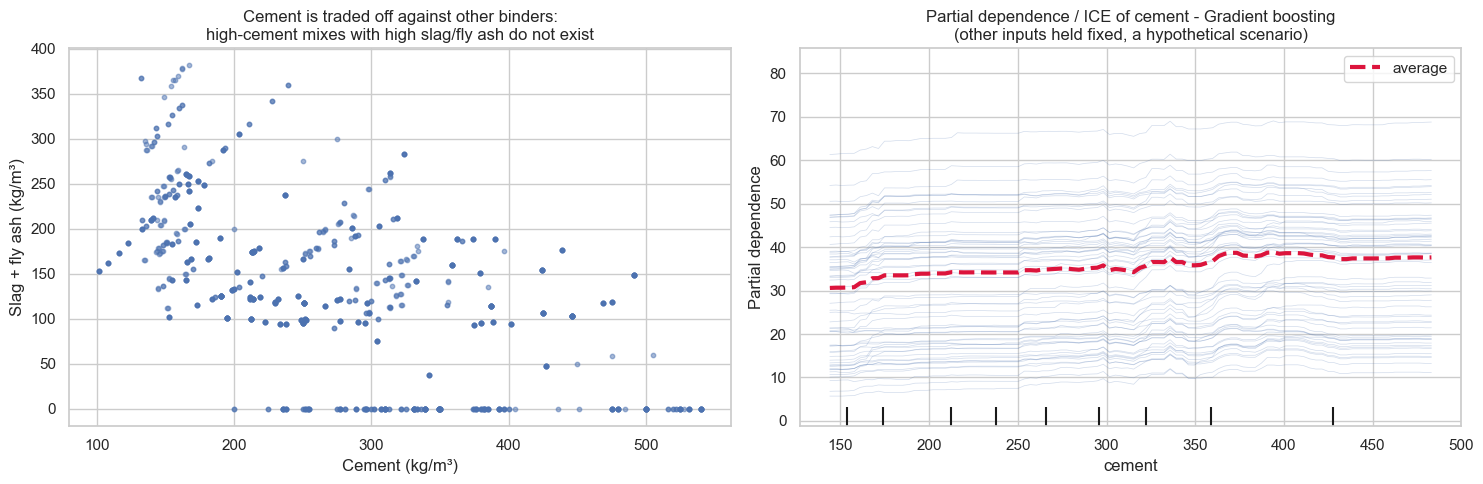

Among the 10% highest-cement mixes, max slag+fly ash = 177 kg/m3 (overall max = 382). The model never saw high-cement mixes with high slag/fly ash,
so its 'what if we add cement' curve for such mixes is an extrapolation.


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
scm_total = data["slag"] + data["fly_ash"]
axes[0].scatter(data["cement"], scm_total, s=10, alpha=.5)
axes[0].set(xlabel="Cement (kg/m³)", ylabel="Slag + fly ash (kg/m³)",
            title="Cement is traded off against other binders:\nhigh-cement mixes with high slag/fly ash do not exist")
m_nl, f_nl, _ = fitted[best_nl]
PartialDependenceDisplay.from_estimator(m_nl, train[f_nl], ["cement"], kind="both", subsample=60,
                                        random_state=RANDOM_STATE, ax=axes[1],
                                        ice_lines_kw={"alpha": .25}, pd_line_kw={"color": "crimson", "lw": 3})
axes[1].set_title(f"Partial dependence / ICE of cement - {best_nl}\n(other inputs held fixed, a hypothetical scenario)")
plt.tight_layout(); plt.show()

hi_cement = data["cement"] > data["cement"].quantile(0.9)
print(f"Among the 10% highest-cement mixes, max slag+fly ash = {scm_total[hi_cement].max():.0f} kg/m3 "
      f"(overall max = {scm_total.max():.0f}). The model never saw high-cement mixes with high slag/fly ash,")
print("so its 'what if we add cement' curve for such mixes is an extrapolation.")

### 10.1 Answer and justification

The data support the statement "*in these past mixes, cement content helps predict strength*". They do **not** prove "*if we add X kg of cement to a mix, strength will rise by Y MPa*". The reasons follow.

1. **The data are observational, not a controlled experiment.** The 1,030 tests were compiled from 17 laboratories (Yeh, 1998). Engineers *designed* the mixes for target strengths, so cement content was chosen together with water, superplasticizer and the other binders, not varied on its own at random. Any of those co-varying factors, plus unrecorded ones (cement type and grade, aggregate quality, curing temperature and humidity, lab practice), can **confound** the association (Pearl, 2009; Hernán & Robins, 2020).

2. **The estimated "cement effect" changes with the model.** The cement coefficient is 0.070 MPa per kg/m³ on its own, 0.115 when the other raw inputs are included, 0.084 with the engineered ratios, and 0.086 for 28-day samples only. That is a 60% swing. A model coefficient describes an association *given the other variables in the model*, not a fixed physical effect.

3. **You cannot change cement "holding everything else constant".** The mixture is a near-fixed budget of about 2,350 kg/m³ (sd 65 kg). Cement is substituted by slag and fly ash (correlation −0.30 and −0.39). Adding cement must displace something else, or change the w/c ratio and the binder share. Which of these happens determines the real outcome. The partial-dependence plot above *does* hold the other inputs fixed. It gives a much flatter curve (about 30 to 38 MPa over the cement range) than the simple slope implies, partly because the model also "holds fixed" the w/c ratio, which physically cannot stay the same when cement alone changes. The model's answer to "what if" depends on how the question is set up. It is not a law of nature.

4. **Extrapolation.** The model has never seen certain combinations. For example, no high-cement mix also contains a lot of slag or fly ash (the scatter plot's empty upper-right region). Predictions for such hypothetical mixes are extrapolations with no support in the data.

5. **Prediction accuracy is not causal validity.** A model can predict well (R² ≈ 0.9) by using any correlated signal. Good predictive performance on similar mixes says nothing about how strength will respond to a deliberate intervention.

**What is true, and how to find the causal answer.** Concrete science gives strong *mechanistic* reasons why cement contributes to strength: hydration products, and the water–cement ratio via Abrams' law (Neville, 2011). The *direction* of the association is therefore plausible. But the **size** of the effect for a particular mix, and whether it holds (very high cement can bring diminishing returns, more heat of hydration and cracking), must be established by **designed experiments**. In such experiments cement is varied systematically while the other proportions are controlled, for example in factorial or mixture designs (Montgomery, 2017), followed by physical strength tests. The predictive model is useful for **screening candidate mixes and generating hypotheses**, not for proving what an intervention will do.

## 11. Conclusions and limitations

- **Baseline:** predicting the mean gives a test RMSE of about 18 MPa (R² ≈ 0).
- **Linear vs non-linear:** a plain linear model explains only about 64% of the variance (test RMSE 10.8 MPa) because strength depends non-linearly on age and ingredient ratios. Domain-informed features bring a linear model down to about 7.1–7.4 MPa. **Gradient boosting is the most accurate model** (test RMSE 5.7 MPa, R² 0.90). It consistently beats the best linear model by about 1.3 MPa across folds and seeds.
- **Weakest predictions:** high-strength concrete (above 60 MPa, systematically under-predicted), complex blended or superplasticized mixes, rarely tested ages, and mixtures with laboratory-specific effects.
- **Validation matters:** ignoring the repeated-mixture structure would overstate accuracy by about 20%.
- **Causality:** the cement–strength association is predictive, not causal. Changing the mix requires designed experiments to confirm the effect.

**Limitations:** small sample (about 430 distinct mixtures); multiple data sources with unrecorded material and curing differences; no measurement-uncertainty information; limited hyper-parameter search. The model should support, not replace, laboratory testing and engineering judgement, especially for structural or safety-critical applications.

## 12. References

- Abrams, D. A. (1919). *Design of concrete mixtures* (Bulletin 1). Structural Materials Research Laboratory, Lewis Institute, Chicago.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Breusch, T. S., & Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation. *Econometrica*, 47(5), 1287–1294.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
- Hernán, M. A., & Robins, J. M. (2020). *Causal Inference: What If*. Chapman & Hall/CRC.
- Montgomery, D. C. (2017). *Design and Analysis of Experiments* (9th ed.). Wiley.
- Neville, A. M. (2011). *Properties of Concrete* (5th ed.). Pearson.
- Pearl, J. (2009). *Causality: Models, Reasoning, and Inference* (2nd ed.). Cambridge University Press.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.
- Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8), 913–929.
- Yeh, I.-C. (1998). Modeling of strength of high-performance concrete using artificial neural networks. *Cement and Concrete Research*, 28(12), 1797–1808.
- Dataset: Yeh, I.-C. (2007). Concrete Compressive Strength [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PK67